# **🏢 Customer Churn Prediction & Analysis**
### 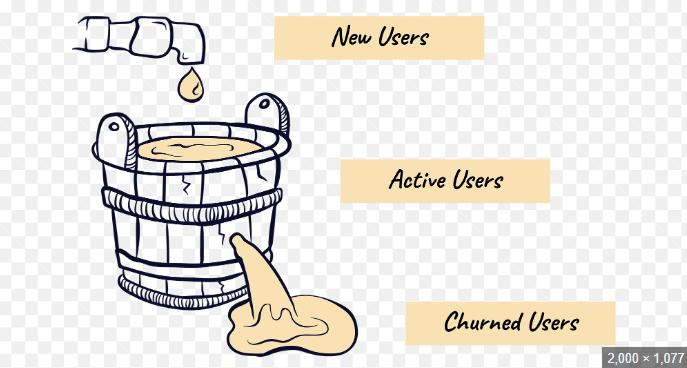
**📝 1. Project Introduction**

🌟 **Overview**

**🏢 Customer Churn Prediction & Analysis**

**📌 Problem Statement**

Telecommunication companies lose revenue when customers leave (churn).

The goal is to identify customers likely to churn and understand the factors influencing churn.




---



**In this project, we will:**

✅ Analyze customer behavior

✅ Identify factors causing churn

✅ Build multiple Machine Learning models

✅ Compare model performance

✅ Generate actionable business insights




---


**🎯2. Business Objective**

* Reduce customer churn
* Improve customer retention
* Identify high-risk customers
* Increase revenue through proactive retention strategie


**📚 3. Import Libraries**

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.decomposition import PCA

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

from sklearn.svm import SVC
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    roc_auc_score
)

**📂 4. Load Dataset**

In [ ]:
df = pd.read_csv("/content/Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


**🧹 5. Data Cleaning**

In [ ]:
df.drop("customerID", axis=1, inplace=True)

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

df["TotalCharges"].fillna(
    df["TotalCharges"].median(),
    inplace=True
)

/tmp/ipykernel_967/3246656213.py:8: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["TotalCharges"].fillna(


**📈 6. Exploratory Data Analysis (EDA)**

   **6.1 Churn Distribution**

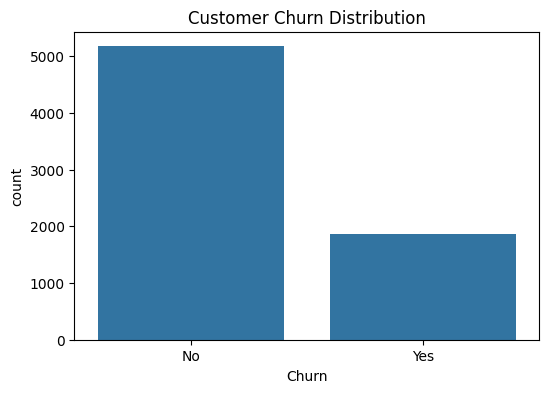

In [ ]:
plt.figure(figsize=(6,4))
sns.countplot(x="Churn", data=df)
plt.title("Customer Churn Distribution")
plt.show()

**6.2 Contract Type vs Churn**

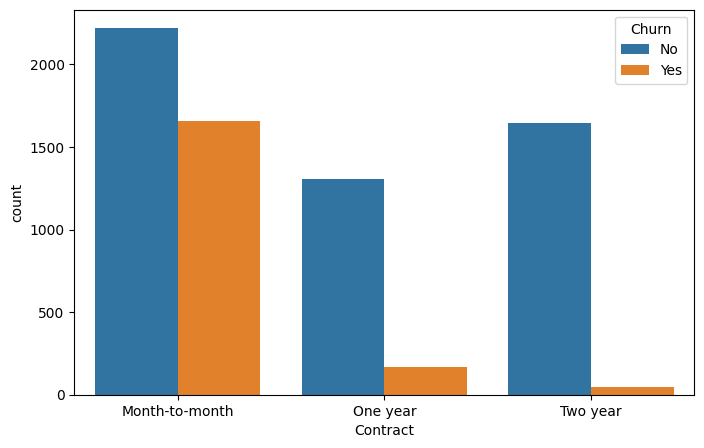

In [ ]:
plt.figure(figsize=(8,5))
sns.countplot(
    x="Contract",
    hue="Churn",
    data=df
)
plt.show()

**6.3 Internet Service vs Churn**

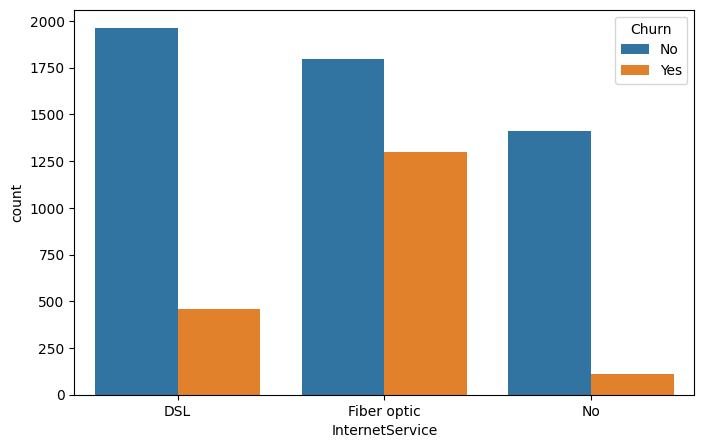

In [ ]:
plt.figure(figsize=(8,5))
sns.countplot(
    x="InternetService",
    hue="Churn",
    data=df
)
plt.show()

**6.4 Monthly Charges Distribution**

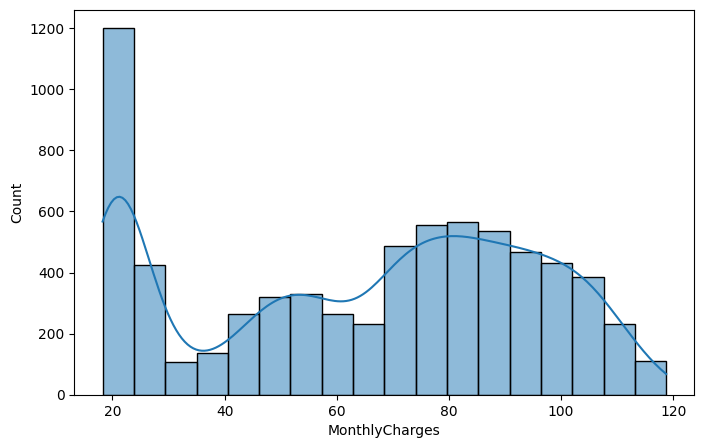

In [ ]:
plt.figure(figsize=(8,5))
sns.histplot(
    df["MonthlyCharges"],
    kde=True
)
plt.show()

**6.5 Tenure vs Churn**

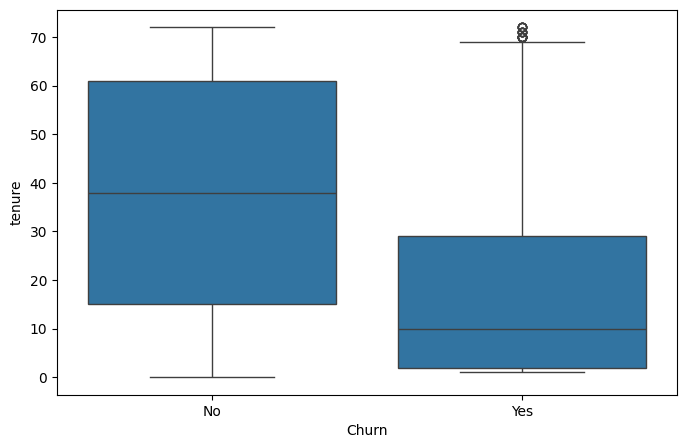

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(
    x="Churn",
    y="tenure",
    data=df
)
plt.show()


**🔥 7. Correlation Heatmap**

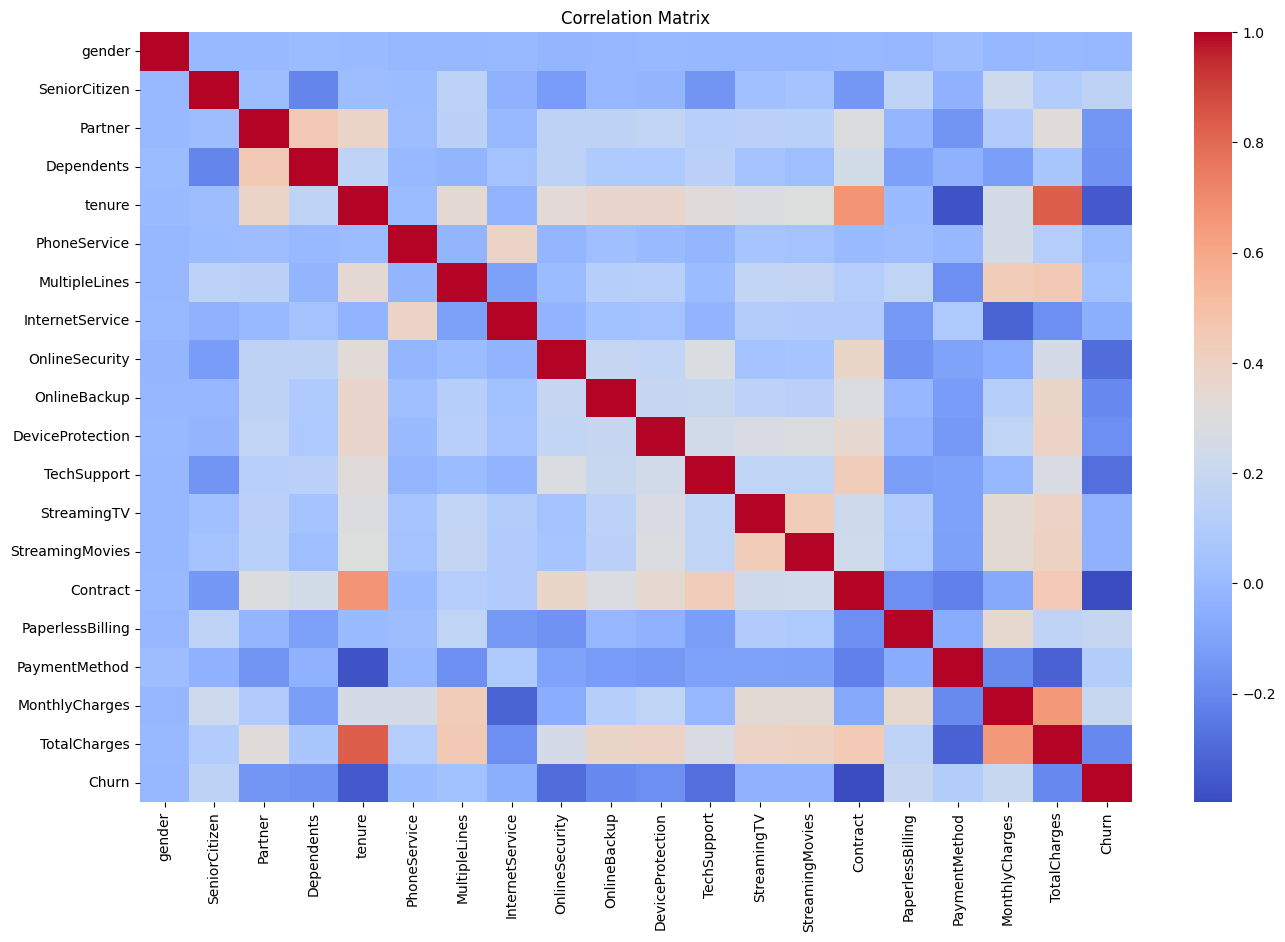

In [ ]:
le = LabelEncoder()

for col in df.columns:
    if df[col].dtype=="object":
        df[col]=le.fit_transform(df[col])

plt.figure(figsize=(16,10))
sns.heatmap(
    df.corr(),
    cmap="coolwarm"
)
plt.title("Correlation Matrix")
plt.show()

**⭐ 8. Feature Importance Analysis**

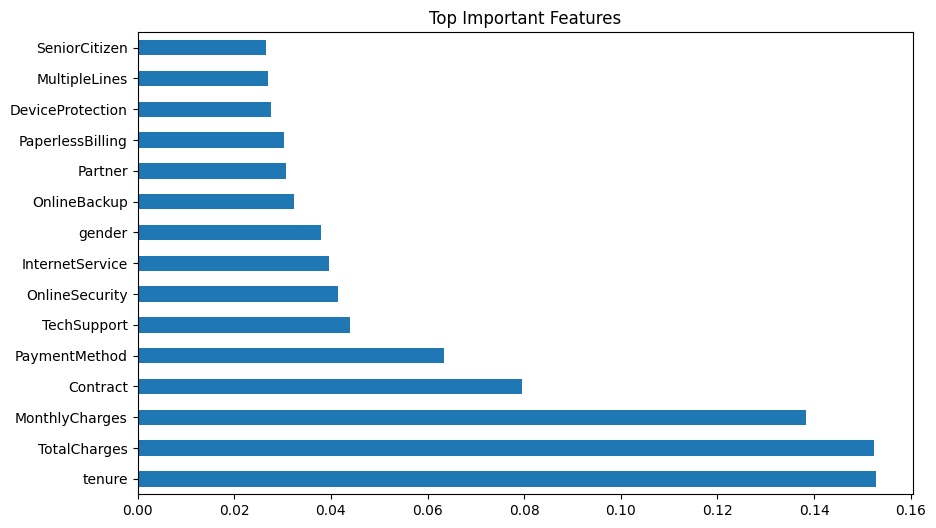

In [ ]:
X = df.drop("Churn", axis=1)
y = df["Churn"]

model = ExtraTreesClassifier()

model.fit(X,y)

feat_importance = pd.Series(
    model.feature_importances_,
    index=X.columns
)

feat_importance.nlargest(15).plot(
    kind="barh",
    figsize=(10,6)
)

plt.title("Top Important Features")
plt.show()

**✂️ 10. Train Test Split**

In [ ]:
X = df.drop("Churn", axis=1)
y = df["Churn"]

X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

**📏 11. Standardization**

In [ ]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

**🧠 12. PCA**

In [ ]:
pca = PCA(n_components=0.95)

X_train = pca.fit_transform(X_train)
X_test = pca.transform(X_test)

print(X_train.shape)

(5634, 16)


**🤖 13. Machine Learning Models**

In [ ]:
models = {

    "Logistic Regression":
        LogisticRegression(max_iter=1000),

    "Decision Tree":
        DecisionTreeClassifier(),

    "Random Forest":
        RandomForestClassifier(
            n_estimators=300
        ),

    "SVM Linear":
        SVC(kernel="linear",
            probability=True),

    "SVM RBF":
        SVC(kernel="rbf",
            probability=True),

    "XGBoost":
        XGBClassifier(
            eval_metric="logloss"
        )
}

**🚀 14. Train Models**

In [ ]:
results=[]

for name, model in models.items():

    model.fit(X_train,y_train)

    pred=model.predict(X_test)

    acc=accuracy_score(y_test,pred)

    results.append([name,acc])

    print("\n",name)
    print("Accuracy:",acc)

    print(classification_report(
        y_test,pred
    ))


 Logistic Regression
Accuracy: 0.7863733144073811
              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1035
           1       0.62      0.50      0.55       374

    accuracy                           0.79      1409
   macro avg       0.73      0.69      0.71      1409
weighted avg       0.78      0.79      0.78      1409


 Decision Tree
Accuracy: 0.7281760113555713
              precision    recall  f1-score   support

           0       0.82      0.80      0.81      1035
           1       0.49      0.53      0.51       374

    accuracy                           0.73      1409
   macro avg       0.66      0.66      0.66      1409
weighted avg       0.74      0.73      0.73      1409


 Random Forest
Accuracy: 0.7693399574166075
              precision    recall  f1-score   support

           0       0.82      0.89      0.85      1035
           1       0.59      0.44      0.51       374

    accuracy                           0.

**📊 15. Confusion Matrix**

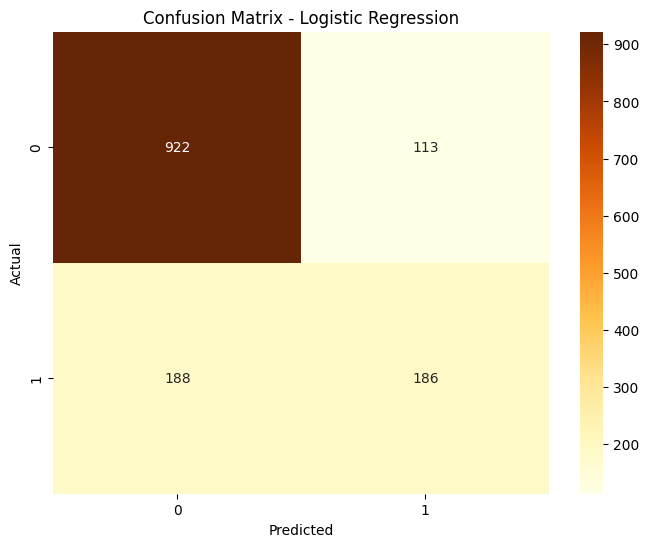

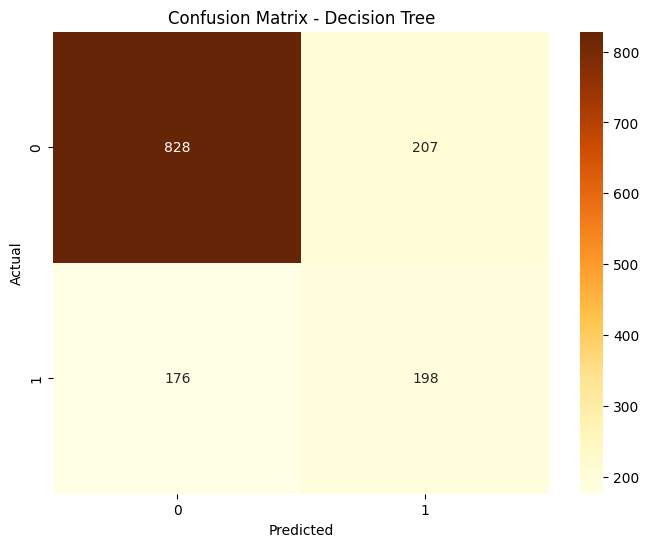

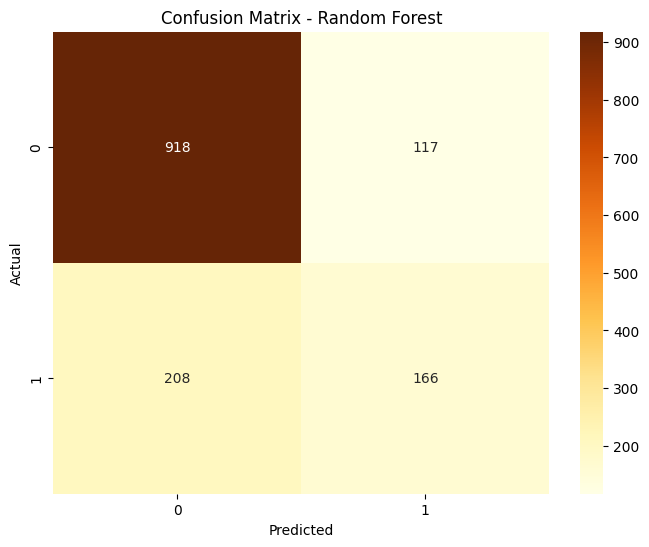

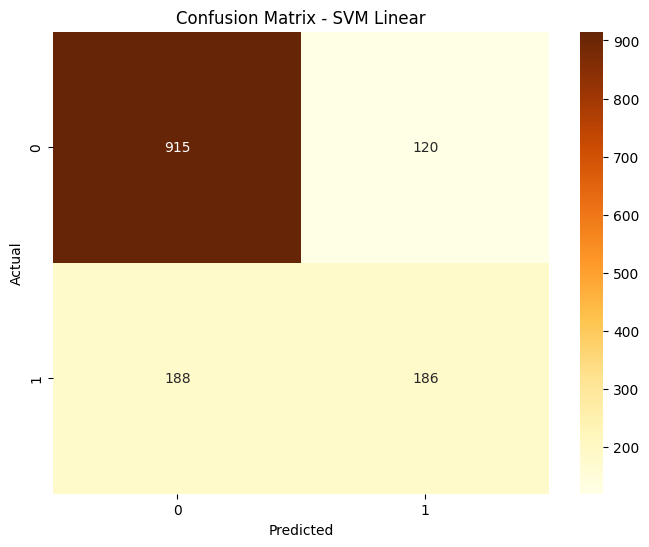

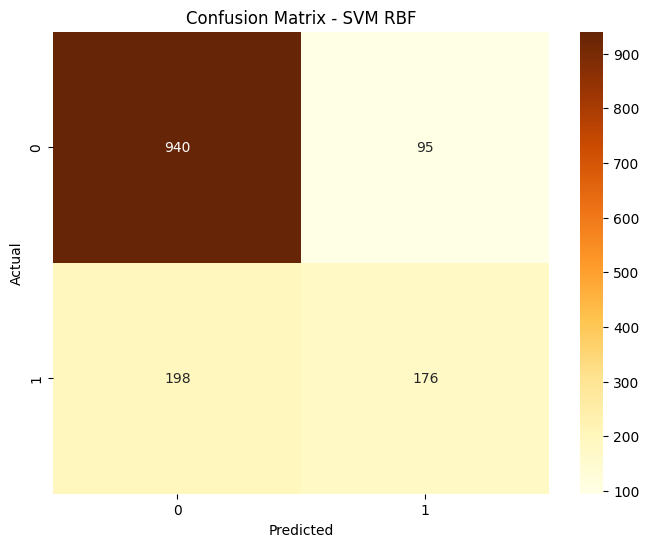

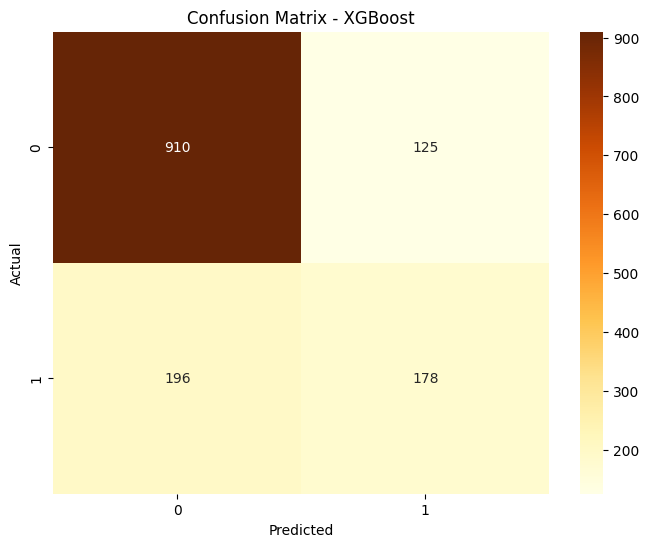

In [ ]:
for name, model in models.items():

    pred=model.predict(X_test)

    cm=confusion_matrix(y_test,pred)

    plt.figure(figsize=(8,6))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='YlOrBr'
    )

    plt.title(f"Confusion Matrix - {name}")

    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.show()

**📈 16. ROC Curve**

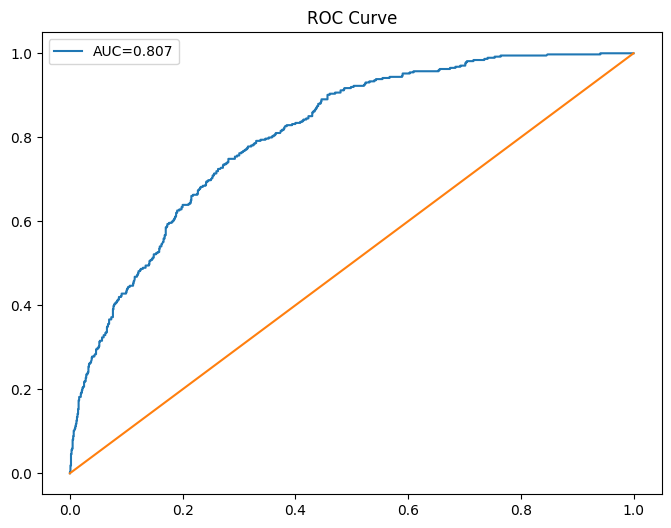

In [ ]:
best_model = XGBClassifier(
    eval_metric="logloss"
)

best_model.fit(X_train,y_train)

y_prob = best_model.predict_proba(
    X_test
)[:,1]

fpr,tpr,_ = roc_curve(
    y_test,
    y_prob
)

auc = roc_auc_score(
    y_test,
    y_prob
)

plt.figure(figsize=(8,6))

plt.plot(
    fpr,
    tpr,
    label=f"AUC={auc:.3f}"
)

plt.plot([0,1],[0,1])

plt.legend()

plt.title("ROC Curve")
plt.show()

**🎯 17. Hyperparameter Tuning (XGBoost)**

In [ ]:
param_grid = {

    'n_estimators':[100,200,300],
    'max_depth':[3,5,7]
}

grid = GridSearchCV(

    XGBClassifier(
        eval_metric='logloss'
    ),

    param_grid,

    cv=5,

    scoring='accuracy'
)

grid.fit(X_train,y_train)

print(grid.best_params_)
print(grid.best_score_)

{'max_depth': 3, 'n_estimators': 100}
0.7774216273890822


**🏆 18. Model Comparison**

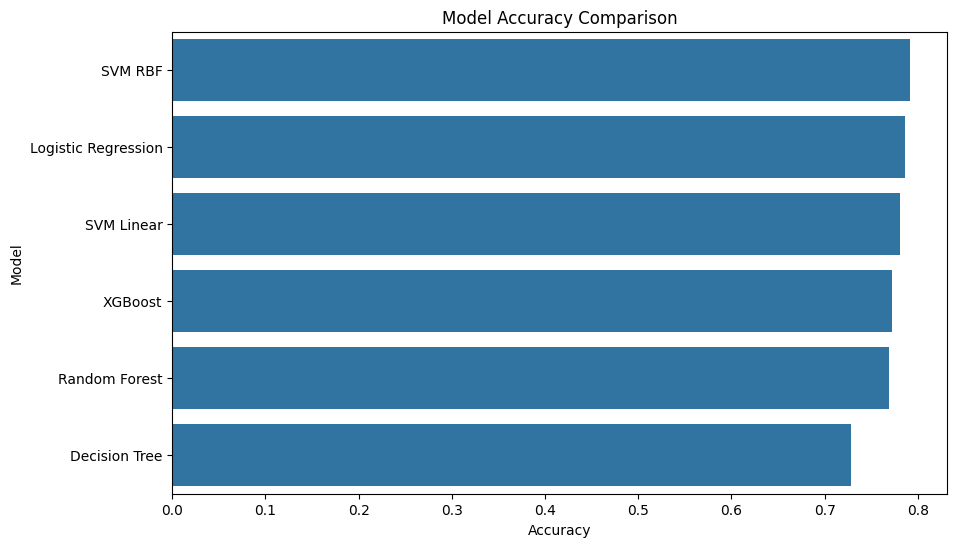

In [ ]:
results_df = pd.DataFrame(
    results,
    columns=["Model","Accuracy"]
)

results_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
)

plt.figure(figsize=(10,6))

sns.barplot(
    x="Accuracy",
    y="Model",
    data=results_df
)

plt.title(
    "Model Accuracy Comparison"
)

plt.show()

**🔮 Predictive Test**

In [ ]:
final_model = SVC(kernel='rbf')

final_model.fit(X_train, y_train)

sample = X_test[0].reshape(1, -1)

prediction = final_model.predict(sample)

actual = y_test.iloc[0]

print("🔮 Predictive Test")
print("-"*40)

print("Actual Value :", actual)
print("Predicted Value :", prediction[0])

if prediction[0] == 1:
    print("⚠️ Customer is likely to Churn")
else:
    print("✅ Customer is likely to Stay")

🔮 Predictive Test
----------------------------------------
Actual Value : 0
Predicted Value : 0
✅ Customer is likely to Stay


**📌 20. Business Insights**

**Key Findings**

✅ Customers with month-to-month contracts churn the most.

✅ Higher monthly charges increase churn risk.

✅ Long-tenure customers are more loyal.

✅ Fiber optic users show higher churn behavior.

✅ Contract type is one of the strongest predictors of churn.

---



**Conclusion**

Successfully developed an end-to-end churn prediction system using multiple machine learning algorithms.

The best-performing model can help telecom companies:

Predict churn early
Improve retention campaigns
Reduce customer loss
Increase revenue